# Simulated vs real drone photos: realism and downstream metrics

Pixel-by-pixel comparison is meaningless (real and simulated photos never show the same texture, and fisheye/tilt warp the edges). So everything here is done **in canvas space**: both photo kinds go through the pipeline's own projection (`make_query`: undistortion, tilt, north-up, same pixel size), then only the central, valid part is used.

Metrics (blocks: `train/simulation/compare.py`, `realism.py`, `downstream.py`):
1. **Downstream** (main): the existing coarse search (edge ZNCC map over the 5.5 km disc) on real and on simulated queries of the same poses: peak error, score of the truth in standard deviations, share of cells scoring above the truth. Also whether the simulated query is hard *for the same photos* that are hard in real.
2. **Realism of the set**: Frechet distance and a real-vs-fake classifier AUC on DINOv2 features and on 11 plain statistics (grey shape, edge/detail level, spectrum slopes, direction spread).
3. **Floor**: the same numbers between two halves of the *real* photos. A fake cannot be expected to beat that floor.

Small, light run: 320 x 256 images, 150 official + 120 NUDT poses, 12 downstream photos. Intervals are bootstrap over photos.

In [1]:
import sys, tempfile
from pathlib import Path
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "src").is_dir() and (p / "train").is_dir())
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
import numpy as np, cv2, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from header import settings, data
from header.satellite_map import SatelliteMap
from train import config
from train.datasets import photo_sets, nudt_data
from train.features.dino_tokens import load_dino
from train.features.edge import EdgeFamily
from train.simulation.camera_model import from_camera
from train.simulation.pose import pose_from_item
from train.simulation.render import render_view
from train.simulation.appearance import regional_detail_with
from train.simulation.compare import summary_vector, SUMMARY_NAMES, frechet_distance, classifier_auc
from train.simulation.realism import dino_features
from train.simulation.downstream import coarse_truth_metrics
from image_processing.geometry import make_query, render_query
from image_processing.map_levels import level_for_height
from image_processing.map_store import build_map_store
from evaluation.testset import truth_in_metres, random_prior

## 0. Settings

In [2]:
SEED = 5
N_OFFICIAL = 150
N_NUDT = 120
N_DOWNSTREAM = 12
CANVAS_SIZE, CANVAS_PIXEL_M = 224, 1.0
LOOKS = {"keep0.00": regional_detail_with(0.0), "keep0.25": regional_detail_with(0.25), "keep0.50": regional_detail_with(0.5),
         "keep1.00": regional_detail_with(1.0), "rule_based": "rule_based", "plain_invert": "plain_invert"}
LOOKS_NUDT = ["keep0.00", "keep0.25", "rule_based", "plain_invert"]
SENSOR_OFFICIAL = dict(vignette=0.35, contrast=1.0, clahe=3.0, grain=0.03, gamma=1.6)     # chosen from a small sweep on these official photos (in-sample), see the notes below
SCRATCH = Path(tempfile.mkdtemp())
encoder = load_dino(CANVAS_SIZE)

/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data: NUDT and official (geometry exactly as the pipeline believes it)

In [3]:
nudt_scene = photo_sets.load_nudt_photos(N_NUDT, seed=SEED, split="valid")
nudt = dict(items=nudt_scene["test_set"].items, map=nudt_scene["satellite_map"], real_camera=nudt_scene["camera"],
            sim_camera=from_camera(nudt_scene["camera"]).scaled(0.25), geometry=dict(settings.GEOMETRY), sensor=None)
dev_dir = config.find_dev_dir()
settings.LEVELS = list(photo_sets.DEV_DEFAULTS["levels"])
settings.GEOMETRY.clear(); settings.GEOMETRY.update(photo_sets.DEV_DEFAULTS["geometry"])
settings.IMAGES_DIR = dev_dir / "d1" / "images"
table_meta = data.read_metadata()
official_camera = data.Camera(table_meta)
all_official = data.make_items(table_meta)
pick = np.random.default_rng(SEED).choice(len(all_official), N_OFFICIAL, replace=False)
official = dict(items=[all_official[int(i)] for i in pick], map=SatelliteMap(next(p for p in sorted((dev_dir / "small_sat_area").iterdir()) if p.suffix == ".tif")),
                real_camera=official_camera, sim_camera=from_camera(official_camera), geometry=dict(settings.GEOMETRY), sensor=SENSOR_OFFICIAL)
print(len(nudt["items"]), "NUDT photos,", len(official["items"]), "official photos")

120 NUDT photos, 150 official photos


## 2. Canvases: real and simulated through the same projection

In [4]:
def canvas_of(item, camera, geometry, pixel_m=CANVAS_PIXEL_M):
    canvas, valid = make_query(item, camera, CANVAS_SIZE, pixel_m, geometry)
    return canvas, valid

def real_canvases(scene):
    canvases, valids = [], []
    for item in scene["items"]:
        canvas, valid = canvas_of(item, scene["real_camera"], scene["geometry"])
        canvases.append(canvas); valids.append(valid)
    return canvases, valids

def sim_canvases(scene, look, seed_base):
    canvases, valids = [], []
    for index, item in enumerate(scene["items"]):
        pose = pose_from_item(item, scene["map"], scene["geometry"])
        result = render_view(scene["map"], scene["sim_camera"], pose, np.random.default_rng([SEED, seed_base, index]), appearance=look, sensor_settings=scene["sensor"])
        path = SCRATCH / ("s_%d_%d.png" % (seed_base, index))
        cv2.imwrite(str(path), result["image"])
        canvas, valid = canvas_of(dict(item, name=str(path)), scene["sim_camera"], scene["geometry"])
        canvases.append(canvas); valids.append(valid)
    return canvases, valids

sets = {}
for scene_name, scene in (("official", official), ("NUDT", nudt)):
    sets[scene_name] = {"real": real_canvases(scene)}
    names = list(LOOKS) if scene_name == "official" else LOOKS_NUDT
    for number, look_name in enumerate(names):
        sets[scene_name][look_name] = sim_canvases(scene, LOOKS[look_name], number)
    print(scene_name, "done:", list(sets[scene_name]))

official done: ['real', 'keep0.00', 'keep0.25', 'keep0.50', 'keep1.00', 'rule_based', 'plain_invert']


NUDT done: ['real', 'keep0.00', 'keep0.25', 'rule_based', 'plain_invert']


## 3. Realism of the set

Per look: **Frechet** (DINO features, shared PCA to 24 dims; lower is closer), **AUC dino** and **AUC stats** (real-vs-fake classifier, 5-fold; 0.5 = cannot tell, 1.0 = always), against the **real-vs-real floor** (two disjoint halves of the real photos; same sample sizes). `frechet +-` is the bootstrap spread over photos.

In [5]:
def features_of(canvas_set):
    canvases, valids = canvas_set
    return dino_features(encoder, canvases, valids), np.array([summary_vector(c, v) for c, v in zip(canvases, valids)])

features = {scene_name: {name: features_of(canvas_set) for name, canvas_set in group.items()} for scene_name, group in sets.items()}

def bootstrap_frechet(a, b, repeats=15, seed=0):
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(repeats):
        values.append(frechet_distance(a[rng.integers(0, len(a), len(a))], b[rng.integers(0, len(b), len(b))]))
    return float(np.std(values))

rows = []
for scene_name, group in features.items():
    real_dino, real_stats = group["real"]
    half = len(real_dino) // 2
    candidates = [("real-vs-real floor", (real_dino[:half], real_stats[:half]), (real_dino[half:2 * half], real_stats[half:2 * half]))]
    for look_name, (sim_dino, sim_stats) in group.items():
        if look_name != "real":
            candidates.append((look_name, (real_dino[:half], real_stats[:half]), (sim_dino[:half], sim_stats[:half])))
    for look_name, (dino_a, stats_a), (dino_b, stats_b) in candidates:
        rows.append(dict(data=scene_name, look=look_name, frechet=round(frechet_distance(dino_a, dino_b), 1), frechet_pm=round(bootstrap_frechet(dino_a, dino_b), 1),
                         auc_dino=round(classifier_auc(dino_a, dino_b)[0], 2), auc_stats=round(classifier_auc(stats_a, stats_b)[0], 2)))
realism_table = pd.DataFrame(rows)
realism_table

,data,look,frechet,frechet_pm,auc_dino,auc_stats
0,official,real-vs-real floor,46.4,18.1,0.38,0.47
1,official,keep0.00,439.3,10.5,1.00,0.99
2,official,keep0.25,404.5,12.2,1.00,0.99
3,official,keep0.50,367.3,12.3,1.00,0.98
4,official,keep1.00,283.5,15.3,1.00,0.99
5,official,rule_based,368.6,14.7,1.00,1.00
6,official,plain_invert,254.5,15.4,1.00,1.00
7,NUDT,real-vs-real floor,255.3,21.4,0.96,0.80
8,NUDT,keep0.00,579.7,18.0,1.00,0.98
9,NUDT,keep0.25,439.8,23.1,1.00,1.00


In [6]:
# which statistic gives the fake away? gap = (fake mean - real mean) / real standard deviation
for scene_name, group in features.items():
    real_stats = group["real"][1]
    gap = {}
    for look_name, (sim_dino, sim_stats) in group.items():
        if look_name != "real":
            gap[look_name] = (sim_stats.mean(axis=0) - real_stats.mean(axis=0)) / (real_stats.std(axis=0) + 1e-9)
    print(scene_name)
    display(pd.DataFrame(gap, index=SUMMARY_NAMES).round(2))

official


,keep0.00,keep0.25,keep0.50,keep1.00,rule_based,plain_invert
q05,-1.39,-1.62,-1.59,-1.74,-1.64,-1.81
q25,-3.00,-3.00,-2.97,-2.96,-2.85,-2.85
q75,0.83,0.76,0.86,0.76,0.80,0.73
q95,-2.02,-2.19,-2.15,-2.21,-2.16,-2.21
skew,-1.74,-1.87,-1.85,-1.92,-1.89,-1.95
edge_strength,-0.93,-0.29,0.40,1.81,-0.18,1.87
fine_detail,-1.26,-0.85,-0.43,0.81,-0.58,1.35
power_slope_low,0.80,1.31,1.64,1.96,0.86,1.83
power_slope_high,1.00,0.85,0.53,0.30,1.36,1.24
orientation_entropy,0.16,0.20,0.19,0.26,0.17,0.29


NUDT


,keep0.00,keep0.25,rule_based,plain_invert
q05,-0.02,-0.30,-0.03,-0.48
q25,0.06,0.15,0.50,0.27
q75,-0.29,-0.47,-0.55,-0.70
q95,-0.22,-0.18,0.17,-0.36
skew,-0.21,-0.21,0.07,-0.44
edge_strength,-1.56,-0.79,-0.79,0.09
fine_detail,-2.69,-1.97,-2.11,0.40
power_slope_low,-0.46,-0.28,-0.63,-0.09
power_slope_high,-5.42,-4.11,-3.97,0.11
orientation_entropy,0.08,0.33,0.46,0.38


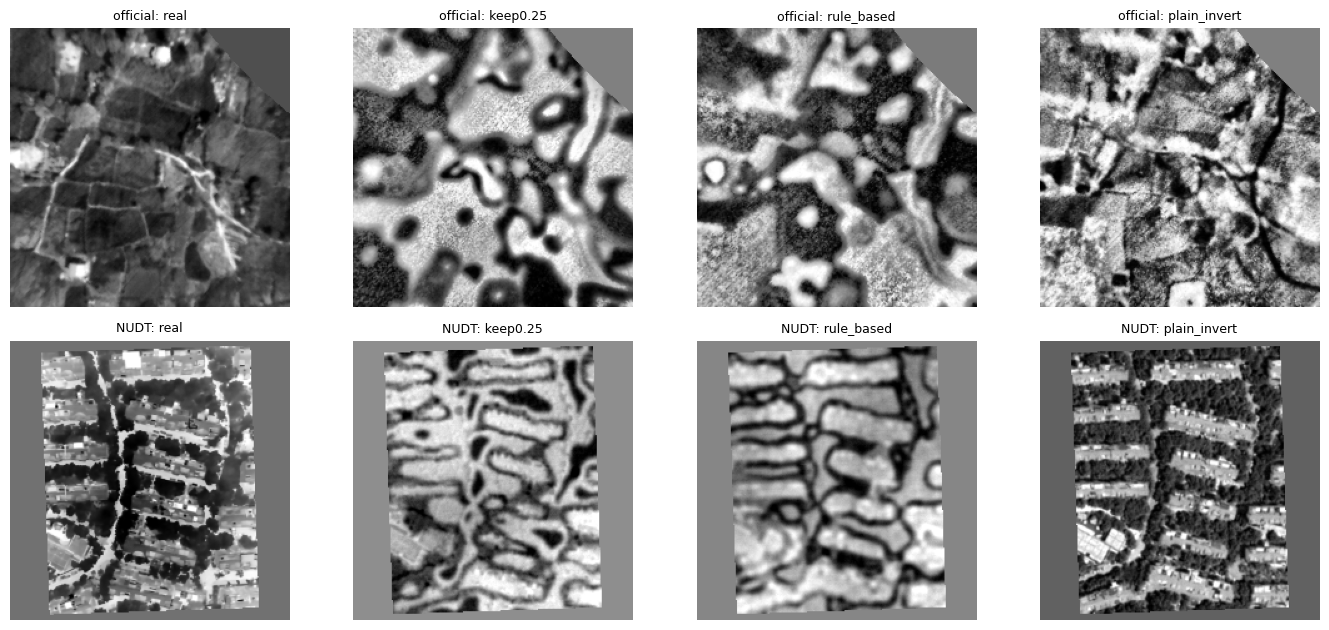

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
for row, scene_name in enumerate(["official", "NUDT"]):
    shown = ["real"] + (["keep0.25", "rule_based", "plain_invert"])
    for column, name in enumerate(shown):
        canvases, valids = sets[scene_name][name]
        axes[row, column].imshow(canvases[3], cmap="gray", vmin=0, vmax=1); axes[row, column].set_title(scene_name + ": " + name, fontsize=9); axes[row, column].axis("off")
plt.tight_layout(); plt.show()

## 4. Downstream: does the coarse search behave the same on real and simulated queries?

Official data only (the whole map is 13840 x 22096 px; map store built for levels 3 to 5, so photos up to about 200 m). Prior = truth + random offset inside 5 km, as in the evaluation. Same function for every query: edge ZNCC map over the disc, then `peak_error_m`, `z_truth`, `truth_percentile`, `margin`.
`hit` = peak within 30 m of the truth. **N is small (12 photos), so this shows direction, not a score.**

In [8]:
settings.LEVELS = [3, 4, 5]
store = build_map_store(official["map"])
families = {"edge": EdgeFamily(store)}
low_items = [item for item in all_official if item["rel_height"] <= 200]
chosen_low = np.random.default_rng(SEED + 1).choice(len(low_items), N_DOWNSTREAM, replace=False)
down_items = [low_items[int(i)] for i in chosen_low]
prior_rng = np.random.default_rng(0)

def downstream_row(item, source, canvas, valid, level, truth, prior):
    metrics = coarse_truth_metrics(canvas, valid, level, truth, prior, families)
    return dict(source=source, **metrics)

records = []
for index, item in enumerate(down_items):
    level = level_for_height(item["rel_height"], official_camera)
    truth = truth_in_metres(item, official["map"])
    prior = random_prior(truth, prior_rng)
    canvas, valid = render_query(item, official_camera, level, official["geometry"])
    records.append(dict(photo=index, **downstream_row(item, "real", canvas, valid, level, truth, prior)))
    pose = pose_from_item(item, official["map"], official["geometry"])
    for number, look_name in enumerate(LOOKS):
        result = render_view(official["map"], official["sim_camera"], pose, np.random.default_rng([SEED, 77, number, index]), appearance=LOOKS[look_name], sensor_settings=SENSOR_OFFICIAL)
        path = SCRATCH / ("d_%d_%d.png" % (number, index))
        cv2.imwrite(str(path), result["image"])
        canvas, valid = render_query(dict(item, name=str(path)), official_camera, level, official["geometry"])
        records.append(dict(photo=index, **downstream_row(item, look_name, canvas, valid, level, truth, prior)))
down = pd.DataFrame(records)
down["hit"] = down["peak_error_m"] <= 30
summary = down.groupby("source", sort=False).agg(hit_rate=("hit", "mean"), median_error_m=("peak_error_m", "median"), median_z=("z_truth", "median"),
                                                  median_percentile=("truth_percentile", "median"), median_margin=("margin", "median")).round(3)
summary

level 3: 0.85 m/pixel, picture 7812 x 4893, map coverage 70%
level 4: 1.20 m/pixel, picture 5524 x 3460, map coverage 70%
level 5: 1.70 m/pixel, picture 3906 x 2446, map coverage 70%


map store ready, took 12 s


,hit_rate,median_error_m,median_z,median_percentile,median_margin
source,,,,,
real,0.833,3.205,2.414,0.0,0.009
keep0.00,0.917,2.284,2.459,0.0,0.042
keep0.25,1.000,1.936,2.519,0.0,0.091
keep0.50,1.000,1.936,2.788,0.0,0.150
keep1.00,1.000,1.936,2.997,0.0,0.239
rule_based,1.000,1.936,2.559,0.0,0.065
plain_invert,1.000,1.936,3.502,0.0,0.429


In [9]:
# per photo: is a photo that is hard for the real query also hard for the simulated one?
real_z = down[down.source == "real"].set_index("photo")["z_truth"]
rows = []
for look_name in LOOKS:
    sim_z = down[down.source == look_name].set_index("photo")["z_truth"]
    rho = spearmanr(real_z.values, sim_z.loc[real_z.index].values)[0]
    rows.append(dict(look=look_name, spearman_z_real_vs_sim=round(float(rho), 2), mean_z_sim_minus_real=round(float((sim_z - real_z).mean()), 2)))
pd.DataFrame(rows)

,look,spearman_z_real_vs_sim,mean_z_sim_minus_real
0,keep0.00,0.87,0.11
1,keep0.25,0.92,0.21
2,keep0.50,0.80,0.45
3,keep1.00,0.83,0.63
4,rule_based,0.87,0.17
5,plain_invert,0.64,1.16


## 5. Reading the results (150 official + 120 NUDT poses, 12 downstream photos: a first look, not a score)

Official sensor for this run: `vignette 0.35, contrast 1.0, clahe 3.0, grain 0.03, gamma 1.6`, chosen from two small sweeps on these same official photos (**in-sample**; an earlier run with `vignette 0.35, contrast 0.6` and no enhancement gave almost the same downstream numbers and a similar AUC).

**Downstream (official, the main metric).** Real queries are the hardest: median margin of the truth over the best wrong cell is 0.009 (real) against 0.042 (`keep0.00`), 0.065 (`rule_based`), 0.09 (`keep0.25`), 0.15, 0.24 (`keep1.00`) and 0.43 (`plain_invert`). The truth's z-score is 2.41 (real) against 2.46 to 3.5. Hit rate (peak within 30 m): real 10 of 12, fakes 11 to 12 of 12. So every fake is at least as easy as real, as in Iteration 1; closest are `keep0.00`, `rule_based` and `keep0.25`. Per photo, the fake's z-score tracks the real one (Spearman 0.80 to 0.92; `plain_invert` 0.64): the same photos are hard in both. Twelve photos only show direction.

**Realism of the set.** Two halves of the real official photos cannot be told apart (floor AUC 0.38 to 0.47, Frechet 46). Every fake is still separated almost perfectly (AUC 0.98 to 1.00, Frechet 250 to 440), also after the sensor change.
The sensor change did what it was meant to: edge strength and fine detail are now within about 1 real standard deviation for `keep0.25`, `rule_based` and `keep0.50` (before: 2.5 to 3.4 too low). **It did not make the fakes harder to tell from real**, because what gives them away is the grey-value distribution: the 25th percentile and skew are 2 to 3 real standard deviations off, the 5th and 95th percentiles 1.4 to 2.2 off, and the gradient distribution has fewer extremes (kurtosis -1). Real frames have a dark body and a bright tail; the fakes do not. Gamma and contrast only moved this a little (sweep: AUC 0.99 to 0.96 at best), so this is a property of the **appearance model** (what is hot), not of the camera chain.
Caveat: on NUDT the real-vs-real floor is already high (AUC 0.96, Frechet 255; mixed day and night flights, 60 photos per half), so its realism numbers cannot be interpreted. This NUDT part was run without the new sensor settings.

**What to do next (not done).** (1) Give the appearance model a heavy-tailed thermal distribution (most of the ground cool, few hot objects) and re-run; the check is the quantile and skew gaps and the AUC, with the downstream margin kept near real. (2) Choose the look by downstream margin (here `keep0.00` to `keep0.25`) and validate on held-out real photos and on NUDT (needs a NUDT map store: heavier, not run). (3) Grain, enhancement and vignette are tuned for the official frames only; do not reuse them for NUDT.
